# Feature engineering for vaccination prediction

Run from top to bottom after `03_data_cleaning_and_preparation.ipynb`. This notebook uses the **same saved respondent split and training-only row filter** and preserves the original cleaning outputs as the comparison baseline. All checks and explanations are here; only three final tables and one JSON are exported to `data_processed/ml_features/`.

We create candidate predictors from survey answers only, never vaccination targets. Candidate features express hypotheses; they are not validated psychological scales, clinical risk scores, or evidence of causation. No model is trained here, so improvements in ROC AUC have not been established.

Survey definitions: [DrivenData data description](https://www.drivendata.org/competitions/66/flushot-learning/page/211/). Opinion code **3 means don't know**, and is not a midpoint. Household counts are capped, and age/income are groups rather than exact measurements.


## 1. Load and validate the existing split

Read original answers by respondent ID to compute transparent scores. Use the already cleaned/encoded baseline for the remaining predictors. The baseline excludes training respondents above 20% unknown; validation and test remain complete. IDs and targets are retained in output tables for alignment, but never passed into the feature-building function.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, 'to_string') else value)

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'data_sets/training_set_features.csv').is_file()
             and (p / 'data_processed/ml_categorical/preprocessing_state.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run preparation notebook 03 first, then start here from this project.')
BASE = ROOT / 'data_processed/ml_categorical'
OUT = ROOT / 'data_processed/ml_features'
ID = 'respondent_id'
TARGETS = ['h1n1_vaccine', 'seasonal_vaccine']
source_labeled = pd.read_csv(ROOT / 'data_sets/training_set_features.csv').set_index(ID)
source_test = pd.read_csv(ROOT / 'data_sets/test_set_features.csv').set_index(ID)
labels = pd.read_csv(ROOT / 'data_sets/training_set_labels.csv').set_index(ID)
baseline_state = json.loads((BASE / 'preprocessing_state.json').read_text())
baseline = {name: pd.read_csv(BASE / f'{name}.csv') for name in ['train', 'validation', 'test']}
answers = {}
for name, table in baseline.items():
    assert table[ID].is_unique and not table[ID].isna().any()
    source = source_test if name == 'test' else source_labeled
    assert set(table[ID]).issubset(source.index)
    answers[name] = source.loc[table[ID]].reset_index(drop=True)
    assert ID not in answers[name] and not set(TARGETS) & set(answers[name].columns)
    if name != 'test':
        pd.testing.assert_frame_equal(table[TARGETS], labels.loc[table[ID], TARGETS].reset_index(drop=True))
    assert list(table[baseline_state['encoded_columns']].columns) == baseline_state['encoded_columns']
assert not set(baseline['train'][ID]) & set(baseline['validation'][ID])
excluded_training_ids = set(baseline_state.get('training_row_filter', {}).get('excluded_respondent_ids', []))
assert not excluded_training_ids & set(baseline['train'][ID])
assert not excluded_training_ids & set(baseline['validation'][ID])
assert set(baseline['train'][ID]) | set(baseline['validation'][ID]) | excluded_training_ids == set(source_labeled.index)
assert baseline['test'][ID].tolist() == source_test.index.tolist()
display(pd.DataFrame([{'dataset': n, 'rows': len(t), 'baseline_predictors': len(baseline_state['encoded_columns'])}
                      for n, t in baseline.items()]))


      dataset   rows  baseline_predictors
0       train  20364                  164
1  validation   5341                  164
2        test  26708                  164


## 2. Fixed feature definitions and hypotheses

All mappings and cutoffs below are chosen from survey definitions, not target correlations or validation/test distributions.

H1N1 and seasonal opinion answers stay separate. No cross-vaccine averages are created. Each question has its own ordered score, don’t-know flag and missing flag.

| Family | Hypothesis and definition | Missing-answer policy |
|---|---|---|
| Prevention | Mean of seven binary preventive behaviors; also hygiene (mask, washing, avoiding face-touching) and contact avoidance | Require 4/7 overall or 2/3 within each subscore; include answer coverage |
| Health context | Fraction answering yes to chronic condition, healthcare work, and infant contact | Require at least two answers; include answer coverage; not a clinical vulnerability score |
| Ordered demographics | Education and income follow their natural order | Normalize rank to 0–1; add a flag for unavailable rank; this assumes equal rank steps, not equal years of education or dollars |
| Ordered knowledge/concern | H1N1 knowledge 0–2 and concern 0–3 | Normalize to 0–1 and preserve missingness |
| Age | Original five groups mapped to 0, 0.25, 0.5, 0.75, 1 | Age is complete, so no extra unknown flag; ordinal ranks do not represent exact years |
| Vaccine-specific opinions | Map known ratings 1,2,4,5 to 0,1/3,2/3,1 separately for each of six questions | Code 3 is an explicit don’t-know flag; missing has its own flag; unavailable score is stored as 0 |

A score unavailable because too few questions were answered is stored as 0 **with coverage retained**, so it remains distinguishable from a genuine zero score. We do not replace an individual missing survey answer with zero or a median.

**Education encoding:** the original categories are unchanged: `< 12 Years`, `12 Years`, `Some College`, and `College Graduate`. Their normalized ordinal values are 0, 1/3, 2/3 and 1, respectively. Unknown education is stored as ordered value 0 **with `education_unknown=1`**, distinguishing it from a recorded `< 12 Years` answer. This encodes order but assumes equal model steps between categories; its value should be compared with original one-hot encoding during evaluation.

Income is represented only by `income_poverty_ordered` (0, 0.5, 1) and `income_poverty_unknown`. No broader income-band indicators are added.

Doctor recommendations, vaccine-specific opinions, insurance, chronic conditions and original age groups remain separately encoded. Four joint doctor-recommendation indicators are created as described below.

**Joint doctor recommendations:** `doctor_recc_both=1` only for H1N1 recommendation=1 and seasonal recommendation=1. `doctor_recc_neither=1` only when both original answers are 0. `doctor_recc_h1n1_only=1` for an explicit H1N1 Yes and seasonal No; `doctor_recc_seasonal_only=1` for an explicit H1N1 No and seasonal Yes. Exactly one of the four indicators is 1 when both answers are known. All four are 0 if either answer is missing; the original recommendation columns and unknown flags are retained.


In [2]:
ORDINAL_MAPS = {
    'age_group': {'18 - 34 Years': 0, '35 - 44 Years': 1, '45 - 54 Years': 2,
                  '55 - 64 Years': 3, '65+ Years': 4},
    'education': {'< 12 Years': 0, '12 Years': 1, 'Some College': 2, 'College Graduate': 3},
    'income_poverty': {'Below Poverty': 0, '<= $75,000, Above Poverty': 1, '> $75,000': 2},
    'h1n1_concern': {0: 0, 1: 1, 2: 2, 3: 3},
    'h1n1_knowledge': {0: 0, 1: 1, 2: 2},
}
ORDINAL_MAX = {col: max(mapping.values()) for col, mapping in ORDINAL_MAPS.items()}
BEHAVIOR_SCORES = {
    'prevention': {'columns': ['behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
                             'behavioral_wash_hands', 'behavioral_large_gatherings',
                             'behavioral_outside_home', 'behavioral_touch_face'], 'minimum_answers': 4},
    'hygiene': {'columns': ['behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_touch_face'],
                'minimum_answers': 2},
    'contact_avoidance': {'columns': ['behavioral_avoidance', 'behavioral_large_gatherings',
                                   'behavioral_outside_home'], 'minimum_answers': 2},
    'health_context': {'columns': ['chronic_med_condition', 'health_worker', 'child_under_6_months'],
                       'minimum_answers': 2},
}

OPINION_COLUMNS = [f'opinion_{vaccine}_{question}'
                   for vaccine in ['h1n1', 'seas']
                   for question in ['risk', 'vacc_effective', 'sick_from_vacc']]
OPINION_SCORE_MAP = {1: 0.0, 2: 1/3, 4: 2/3, 5: 1.0}


## 3. Build scores and ordered features

The function receives only original predictors. It uses no fitted statistics, target labels, or other respondents. The six opinion questions each use an ordered score with separate don’t-know and missing flags, distinguishing don't-know from unanswered. Doctor recommendations and other source answers remain separate model inputs; the joint recommendation features represent both vaccines, neither vaccine, H1N1 only and seasonal only, requiring both original answers to be known. Only behavior and health-context questions are aggregated into scores.


In [3]:
def engineer_features(frame):
    assert ID not in frame and not set(TARGETS) & set(frame.columns)
    out = pd.DataFrame(index=frame.index)
    for col, mapping in ORDINAL_MAPS.items():
        values = frame[col].map(mapping)
        # Fail rather than silently treating a new recorded category as missing.
        if (frame[col].notna() & values.isna()).any():
            raise ValueError(f'Unexpected ordinal category in {col}')
        if col == 'age_group':
            if values.isna().any():
                raise ValueError('Age is complete in the source data; review new missing ages before using the one-column encoding.')
            out['age_group_ordered'] = values / ORDINAL_MAX[col]
        else:
            out[f'{col}_ordered'] = values.div(ORDINAL_MAX[col]).fillna(0.0)
            out[f'{col}_unknown'] = values.isna().astype(int)
    for name, recipe in BEHAVIOR_SCORES.items():
        block = frame[recipe['columns']].apply(pd.to_numeric)
        if (block.notna() & ~block.isin([0, 1])).any().any():
            raise ValueError(f'Invalid binary response in {name}')
        answered = block.notna().sum(axis=1)
        out[f'{name}_score'] = block.mean(axis=1).where(answered >= recipe['minimum_answers']).fillna(0.0)
        out[f'{name}_coverage'] = answered / len(recipe['columns'])
    for col in OPINION_COLUMNS:
        values = pd.to_numeric(frame[col])
        if (values.notna() & ~values.isin([1, 2, 3, 4, 5])).any():
            raise ValueError(f'Invalid opinion code in {col}')
        out[f'{col}_score'] = values.map(OPINION_SCORE_MAP).fillna(0.0)
        out[f'{col}_dont_know'] = values.eq(3).astype(int)
        out[f'{col}_unknown'] = values.isna().astype(int)
    # Recommendation patterns require both answers to be known; a blank is never No.
    recommendations = frame[['doctor_recc_h1n1', 'doctor_recc_seasonal']].apply(pd.to_numeric)
    if (recommendations.notna() & ~recommendations.isin([0, 1])).any().any():
        raise ValueError('Invalid doctor recommendation code')
    out['doctor_recc_both'] = recommendations.eq(1).all(axis=1).astype(int)
    out['doctor_recc_neither'] = recommendations.eq(0).all(axis=1).astype(int)
    out['doctor_recc_h1n1_only'] = (
        recommendations['doctor_recc_h1n1'].eq(1) & recommendations['doctor_recc_seasonal'].eq(0)
    ).astype(int)
    out['doctor_recc_seasonal_only'] = (
        recommendations['doctor_recc_h1n1'].eq(0) & recommendations['doctor_recc_seasonal'].eq(1)
    ).astype(int)
    return out.astype(float)

engineered = {name: engineer_features(frame) for name, frame in answers.items()}
print('Engineered columns:', len(engineered['train'].columns))
display(engineered['train'].head())


Engineered columns: 39
   age_group_ordered  education_ordered  education_unknown  income_poverty_ordered  income_poverty_unknown  h1n1_concern_ordered  h1n1_concern_unknown  h1n1_knowledge_ordered  h1n1_knowledge_unknown  prevention_score  prevention_coverage  hygiene_score  hygiene_coverage  contact_avoidance_score  contact_avoidance_coverage  health_context_score  health_context_coverage  opinion_h1n1_risk_score  opinion_h1n1_risk_dont_know  opinion_h1n1_risk_unknown  opinion_h1n1_vacc_effective_score  opinion_h1n1_vacc_effective_dont_know  opinion_h1n1_vacc_effective_unknown  opinion_h1n1_sick_from_vacc_score  opinion_h1n1_sick_from_vacc_dont_know  opinion_h1n1_sick_from_vacc_unknown  opinion_seas_risk_score  opinion_seas_risk_dont_know  opinion_seas_risk_unknown  opinion_seas_vacc_effective_score  opinion_seas_vacc_effective_dont_know  opinion_seas_vacc_effective_unknown  opinion_seas_sick_from_vacc_score  opinion_seas_sick_from_vacc_dont_know  opinion_seas_sick_from_vacc_unknown 

## 4. Replace original behavioral inputs with aggregate scores

Replace the one-hot representations of education, income, knowledge and concern with their ordered values plus explicit unknown flags. This preserves order in the model matrix. Replace age-group indicators with one ordered age score. Replace each opinion question’s indicators with its ordered score and separate don’t-know and missing flags. Keep separate indicators for every observed nominal category, with no omitted reference group. Numeric binary questions and insurance retain their compact value/unknown encoding. Ordered scores impose equally spaced rank steps for a linear model; their predictive value must be evaluated.

All engineered values are in 0–1, so this step needs no learned scaling or imputation. The original baseline encoding vocabulary and rare-category rules remain fitted on training respondents only. Whether ordered representations or these extra features help must be assessed against the unchanged baseline during modeling.

The prevention score includes all seven original `behavioral_*` questions; hygiene and contact avoidance summarize subsets. Remove their individual encoded inputs from the final matrix and keep the score/coverage pairs. Health context is a separate health-related summary; its original health questions remain as individual inputs. This compresses behavioral patterns and does not guarantee equivalent predictive performance. The original answers remain in the raw data and baseline version.


In [4]:
ordinal_replaced_columns = [column for source in ORDINAL_MAPS
                            for column in baseline_state['feature_columns_by_source'][source]]
original_behavior_columns = [col for col in answers['train'] if col.startswith('behavioral_')]
assert set(original_behavior_columns) == set(BEHAVIOR_SCORES['prevention']['columns'])
assert len(original_behavior_columns) == 7
behavior_replaced_columns = [column for source in original_behavior_columns
                             for column in baseline_state['feature_columns_by_source'][source]]
opinion_replaced_columns = [column for source in OPINION_COLUMNS
                            for column in baseline_state['feature_columns_by_source'][source]]
replaced_columns = ordinal_replaced_columns + behavior_replaced_columns + opinion_replaced_columns
behavior_replacement_summary = pd.DataFrame([
    {'original_question': col,
     'included_in_scores': ', '.join(name for name, recipe in BEHAVIOR_SCORES.items() if col in recipe['columns'])}
    for col in original_behavior_columns
])
display(behavior_replacement_summary)
print('Individual behavioral encoding columns removed:', len(behavior_replaced_columns))
retained_columns = [c for c in baseline_state['encoded_columns'] if c not in replaced_columns]
matrices = {}
for name in answers:
    original = baseline[name][retained_columns].reset_index(drop=True)
    matrices[name] = pd.concat([original, engineered[name].reset_index(drop=True)], axis=1)
feature_columns = matrices['train'].columns.tolist()
display(pd.DataFrame([
    {'dataset': name, 'rows': len(matrix), 'retained_baseline_columns': len(retained_columns),
     'engineered_columns': len(engineered[name].columns), 'final_predictors': matrix.shape[1]}
    for name, matrix in matrices.items()
]))
print('Ordered source columns:', list(ORDINAL_MAPS))


             original_question             included_in_scores
0    behavioral_antiviral_meds                     prevention
1         behavioral_avoidance  prevention, contact_avoidance
2         behavioral_face_mask            prevention, hygiene
3        behavioral_wash_hands            prevention, hygiene
4  behavioral_large_gatherings  prevention, contact_avoidance
5      behavioral_outside_home  prevention, contact_avoidance
6        behavioral_touch_face            prevention, hygiene
Individual behavioral encoding columns removed: 14
      dataset   rows  retained_baseline_columns  engineered_columns  final_predictors
0       train  20364                         91                  39               130
1  validation   5341                         91                  39               130
2        test  26708                         91                  39               130
Ordered source columns: ['age_group', 'education', 'income_poverty', 'h1n1_concern', 'h1n1_knowledge']


## 5. Verify feature meaning, missingness and leakage

Use explicit examples to test behavior/health score calculations, coverage, demographic order and preservation of the original source variables. Missing answers must never be counted as “No.” Scores must not depend on other rows or their order. Validate complete numeric matrices and unchanged respondent/target alignment.


In [5]:
fixture = answers['train'].head(5).copy().reset_index(drop=True)
for recipe in BEHAVIOR_SCORES.values():
    fixture.loc[:, recipe['columns']] = np.nan
fixture.loc[0, BEHAVIOR_SCORES['prevention']['columns']] = 1
fixture.loc[1, BEHAVIOR_SCORES['prevention']['columns']] = 0
fixture.loc[2, BEHAVIOR_SCORES['prevention']['columns'][:4]] = [1, 1, 0, 0]
fixture.loc[3, BEHAVIOR_SCORES['prevention']['columns'][:3]] = [1, 1, 1]
fixture.loc[0, ['doctor_recc_h1n1', 'opinion_h1n1_risk', 'opinion_h1n1_vacc_effective', 'health_insurance']] = [1, 5, 4, 1]
fixture.loc[0, 'opinion_seas_risk'] = 1
fixture.loc[0, 'age_group'] = '65+ Years'
fixture.loc[1, 'age_group'] = '18 - 34 Years'
fixture.loc[2, 'age_group'] = '45 - 54 Years'
fixture.loc[4, ['income_poverty', 'h1n1_knowledge']] = None
check = engineer_features(fixture)
assert check.prevention_score.tolist() == [1, 0, .5, 0, 0]
assert np.isclose(check.loc[2, 'prevention_coverage'], 4/7)
assert check.loc[3, 'prevention_coverage'] == 3/7
assert check.loc[4, 'prevention_coverage'] == 0
pd.testing.assert_frame_equal(check.loc[[2]], engineer_features(fixture.loc[[2]]))
pd.testing.assert_frame_equal(check.sort_index(), engineer_features(fixture.iloc[::-1]).sort_index())
for col, mapping in ORDINAL_MAPS.items():
    levels = sorted(mapping, key=mapping.get)
    ordered_fixture = pd.concat([answers['train'].iloc[[0]]] * len(levels), ignore_index=True)
    ordered_fixture[col] = levels
    assert engineer_features(ordered_fixture)[f'{col}_ordered'].is_monotonic_increasing
invalid = fixture.copy()
invalid.loc[0, 'opinion_h1n1_risk'] = 99
try:
    engineer_features(invalid)
except ValueError:
    pass
else:
    raise AssertionError('Invalid opinion code was not rejected')
for name, matrix in matrices.items():
    assert matrix.columns.is_unique and matrix.columns.tolist() == feature_columns
    assert matrix.shape[0] == len(baseline[name])
    assert np.isfinite(matrix.to_numpy(dtype=float)).all()
    assert matrix.ge(0).all().all() and matrix.le(1).all().all()
    assert ID not in matrix and not set(TARGETS) & set(matrix.columns)
    # Check unknown remains separate from non-employment and rare groups.
    assert 'employment_industry=Unknown' in matrix
    assert 'employment_industry=not_employed' in matrix
    assert 'employment_industry=__Other__' in matrix
# Cross-vaccine opinion summaries and their helper columns must be absent.
removed_opinion_families = ['risk_perception', 'effectiveness_belief', 'vaccine_illness_worry']
assert not any(c.startswith(f'{family}_') for c in feature_columns for family in removed_opinion_families)
# Each original opinion answer is recoverable from its score and two flags.
for col in OPINION_COLUMNS:
    assert not any(c.startswith(f'{col}=') for c in feature_columns)
    for name in matrices:
        matrix = matrices[name]
        score = matrix[f'{col}_score']
        dont_know = matrix[f'{col}_dont_know'].eq(1)
        unknown = matrix[f'{col}_unknown'].eq(1)
        assert not (dont_know & unknown).any()
        decoded = score.mul(3).round().map({0: 1, 1: 2, 2: 4, 3: 5})
        decoded.loc[dont_know] = 3
        decoded.loc[unknown] = np.nan
        pd.testing.assert_series_equal(decoded, answers[name][col], check_names=False, check_dtype=False)
# Check all six possible response states explicitly, independently for each question.
opinion_fixture = pd.concat([answers['train'].iloc[[0]]] * 6, ignore_index=True)
for col in OPINION_COLUMNS:
    opinion_fixture[col] = [1, 2, 3, 4, 5, np.nan]
opinion_check = engineer_features(opinion_fixture)
for col in OPINION_COLUMNS:
    assert np.allclose(opinion_check[f'{col}_score'], [0, 1/3, 0, 2/3, 1, 0])
    assert opinion_check[f'{col}_dont_know'].tolist() == [0, 0, 1, 0, 0, 0]
    assert opinion_check[f'{col}_unknown'].tolist() == [0, 0, 0, 0, 0, 1]
    assert not opinion_check[[f'{col}_score', f'{col}_dont_know', f'{col}_unknown']].duplicated().any()
assert len(engineered['train'].columns) == 39
assert not any(col.startswith('behavioral_') for col in feature_columns)
for family in BEHAVIOR_SCORES:
    assert f'{family}_score' in feature_columns
    assert f'{family}_coverage' in feature_columns
# Every removed behavioral question is covered by prevention, with subsets documented.
assert set(original_behavior_columns) == set(BEHAVIOR_SCORES['prevention']['columns'])
assert len(behavior_replaced_columns) == 14
removed_interactions = [
    'h1n1_recommended_and_high_risk', 'h1n1_recommended_and_effective',
    'h1n1_insured_and_recommended', 'seasonal_recommended_and_high_risk',
    'seasonal_recommended_and_effective', 'seasonal_insured_and_recommended',
    'senior_and_chronic_condition',
]
assert not set(removed_interactions) & set(feature_columns)
# Preserve each original interaction-source variable separately, without alteration.
original_sources = ['doctor_recc_h1n1', 'doctor_recc_seasonal',
                    'health_insurance', 'chronic_med_condition']
for source in original_sources:
    source_columns = baseline_state['feature_columns_by_source'][source]
    assert source_columns and set(source_columns).issubset(feature_columns)
    for name in matrices:
        pd.testing.assert_frame_equal(matrices[name][source_columns], baseline[name][source_columns], check_dtype=False)
assert not any(col.startswith('income_band=') for col in feature_columns)
assert 'income_poverty_ordered' in feature_columns and 'income_poverty_unknown' in feature_columns
assert 'age_group_ordered' in feature_columns
assert 'age_group_unknown' not in feature_columns
assert not any(col.startswith(('age_group=', 'age_band=')) for col in feature_columns)
for name in matrices:
    expected_age = answers[name]['age_group'].map(ORDINAL_MAPS['age_group']) / 4
    pd.testing.assert_series_equal(matrices[name]['age_group_ordered'], expected_age, check_names=False)
# Preserve every original age group distinctly, including 18-34 at value zero.
age_fixture = pd.concat([answers['train'].iloc[[0]]] * 5, ignore_index=True)
age_fixture['age_group'] = list(ORDINAL_MAPS['age_group'])
assert engineer_features(age_fixture)['age_group_ordered'].tolist() == [0, .25, .5, .75, 1]
for source in ['doctor_recc_h1n1', 'doctor_recc_seasonal', 'health_insurance', 'chronic_med_condition']:
    assert source in feature_columns
    assert f'{source}_unknown' in feature_columns
    assert f'{source}=0' not in feature_columns
assert len(feature_columns) == len(retained_columns) + len(engineered['train'].columns)
print('All score examples, ordered mappings, unknown handling, row-independence and schema checks passed.')

# Explicit indicators keep every nominal category visible in the final heatmap.
for source in ['race', 'sex', 'marital_status', 'rent_or_own', 'employment_status',
               'hhs_geo_region', 'census_msa', 'household_adults', 'household_children',
               'employment_industry', 'employment_occupation']:
    columns = baseline_state['feature_columns_by_source'][source]
    assert baseline_state['encoding'][source]['reference'] is None
    assert set(columns).issubset(feature_columns)
    for name in matrices:
        assert matrices[name][columns].sum(axis=1).eq(1).all()
assert 'race=Black' in feature_columns
assert 'sex=Male' in feature_columns
assert 'marital_status=Not Married' in feature_columns
assert 'rent_or_own=Rent' in feature_columns

# Check all nine combinations, including partial and complete missingness.
recommendation_pairs = [(h1n1, seasonal) for h1n1 in [0, 1, np.nan] for seasonal in [0, 1, np.nan]]
recommendation_fixture = pd.concat([answers['train'].iloc[[0]]] * 9, ignore_index=True)
recommendation_fixture[['doctor_recc_h1n1', 'doctor_recc_seasonal']] = recommendation_pairs
recommendation_check = engineer_features(recommendation_fixture)
assert recommendation_check['doctor_recc_both'].tolist() == [0, 0, 0, 0, 1, 0, 0, 0, 0]
assert recommendation_check['doctor_recc_neither'].tolist() == [1, 0, 0, 0, 0, 0, 0, 0, 0]
assert recommendation_check['doctor_recc_h1n1_only'].tolist() == [0, 0, 0, 1, 0, 0, 0, 0, 0]
assert recommendation_check['doctor_recc_seasonal_only'].tolist() == [0, 1, 0, 0, 0, 0, 0, 0, 0]
recommendation_pattern_columns = ['doctor_recc_both', 'doctor_recc_neither',
                                  'doctor_recc_h1n1_only', 'doctor_recc_seasonal_only']
assert recommendation_check[recommendation_pattern_columns].sum(axis=1).tolist() == [1, 1, 0, 1, 1, 0, 0, 0, 0]
for name, matrix in matrices.items():
    source = answers[name][['doctor_recc_h1n1', 'doctor_recc_seasonal']]
    assert matrix['doctor_recc_both'].tolist() == source.eq(1).all(axis=1).astype(float).tolist()
    assert matrix['doctor_recc_neither'].tolist() == source.eq(0).all(axis=1).astype(float).tolist()
    assert matrix['doctor_recc_h1n1_only'].tolist() == (source['doctor_recc_h1n1'].eq(1) & source['doctor_recc_seasonal'].eq(0)).astype(float).tolist()
    assert matrix['doctor_recc_seasonal_only'].tolist() == (source['doctor_recc_h1n1'].eq(0) & source['doctor_recc_seasonal'].eq(1)).astype(float).tolist()
    complete = source.notna().all(axis=1)
    assert matrix.loc[complete, recommendation_pattern_columns].sum(axis=1).eq(1).all()
    assert matrix.loc[~complete, recommendation_pattern_columns].eq(0).all().all()
invalid_recommendation = recommendation_fixture.copy()
invalid_recommendation.loc[0, 'doctor_recc_h1n1'] = 2
try:
    engineer_features(invalid_recommendation)
except ValueError:
    pass
else:
    raise AssertionError('Invalid doctor recommendation was not rejected')


All score examples, ordered mappings, unknown handling, row-independence and schema checks passed.


## 6. Inspect the training features

Inspect distributions on training respondents. Coverage indicates the number of usable answers behind each aggregate; compare it when interpreting score values. No validation/test target correlations are used to select these features. The hypotheses and thresholds still need evaluation during modeling.


In [6]:
inspection = engineered['train'].describe().T[['count', 'mean', 'std', 'min', 'max']]
inspection['zero_variance'] = engineered['train'].nunique().le(1)
display(inspection)
print('Zero-variance candidate columns:', inspection.index[inspection.zero_variance].tolist())


                                         count      mean       std       min  max  zero_variance
age_group_ordered                      20364.0  0.553489  0.363479  0.000000  1.0          False
education_ordered                      20364.0  0.656698  0.336103  0.000000  1.0          False
education_unknown                      20364.0  0.006286  0.079034  0.000000  1.0          False
income_poverty_ordered                 20364.0  0.518930  0.353455  0.000000  1.0          False
income_poverty_unknown                 20364.0  0.125123  0.330866  0.000000  1.0          False
h1n1_concern_ordered                   20364.0  0.537435  0.301507  0.000000  1.0          False
h1n1_concern_unknown                   20364.0  0.002995  0.054650  0.000000  1.0          False
h1n1_knowledge_ordered                 20364.0  0.633888  0.308238  0.000000  1.0          False
h1n1_knowledge_unknown                 20364.0  0.004370  0.065966  0.000000  1.0          False
prevention_score              

### Triangular heatmap of engineered features

This heatmap compares all **39 engineered columns**, including scores, coverage, ordered encodings and four joint doctor-recommendation indicators. It uses only the retained training respondents; vaccination targets and validation/test data are excluded.

Each pair appears once in the lower triangle; the diagonal is hidden. **Red** indicates positive Spearman rank correlation, **blue** negative correlation, and pale cells correlation near zero. **Grey N/A** means correlation is undefined because one column is constant in training. Hover over a cell for its feature pair, correlation and sample size.

Strong correlations are expected between overlapping behavior scores and their component features. Unavailable aggregate scores are stored as zero with coverage recorded separately, so missingness patterns can also influence correlations. This is a descriptive view, not a measure of target importance or a reason to automatically remove a feature. The SVG can be opened separately for zooming.


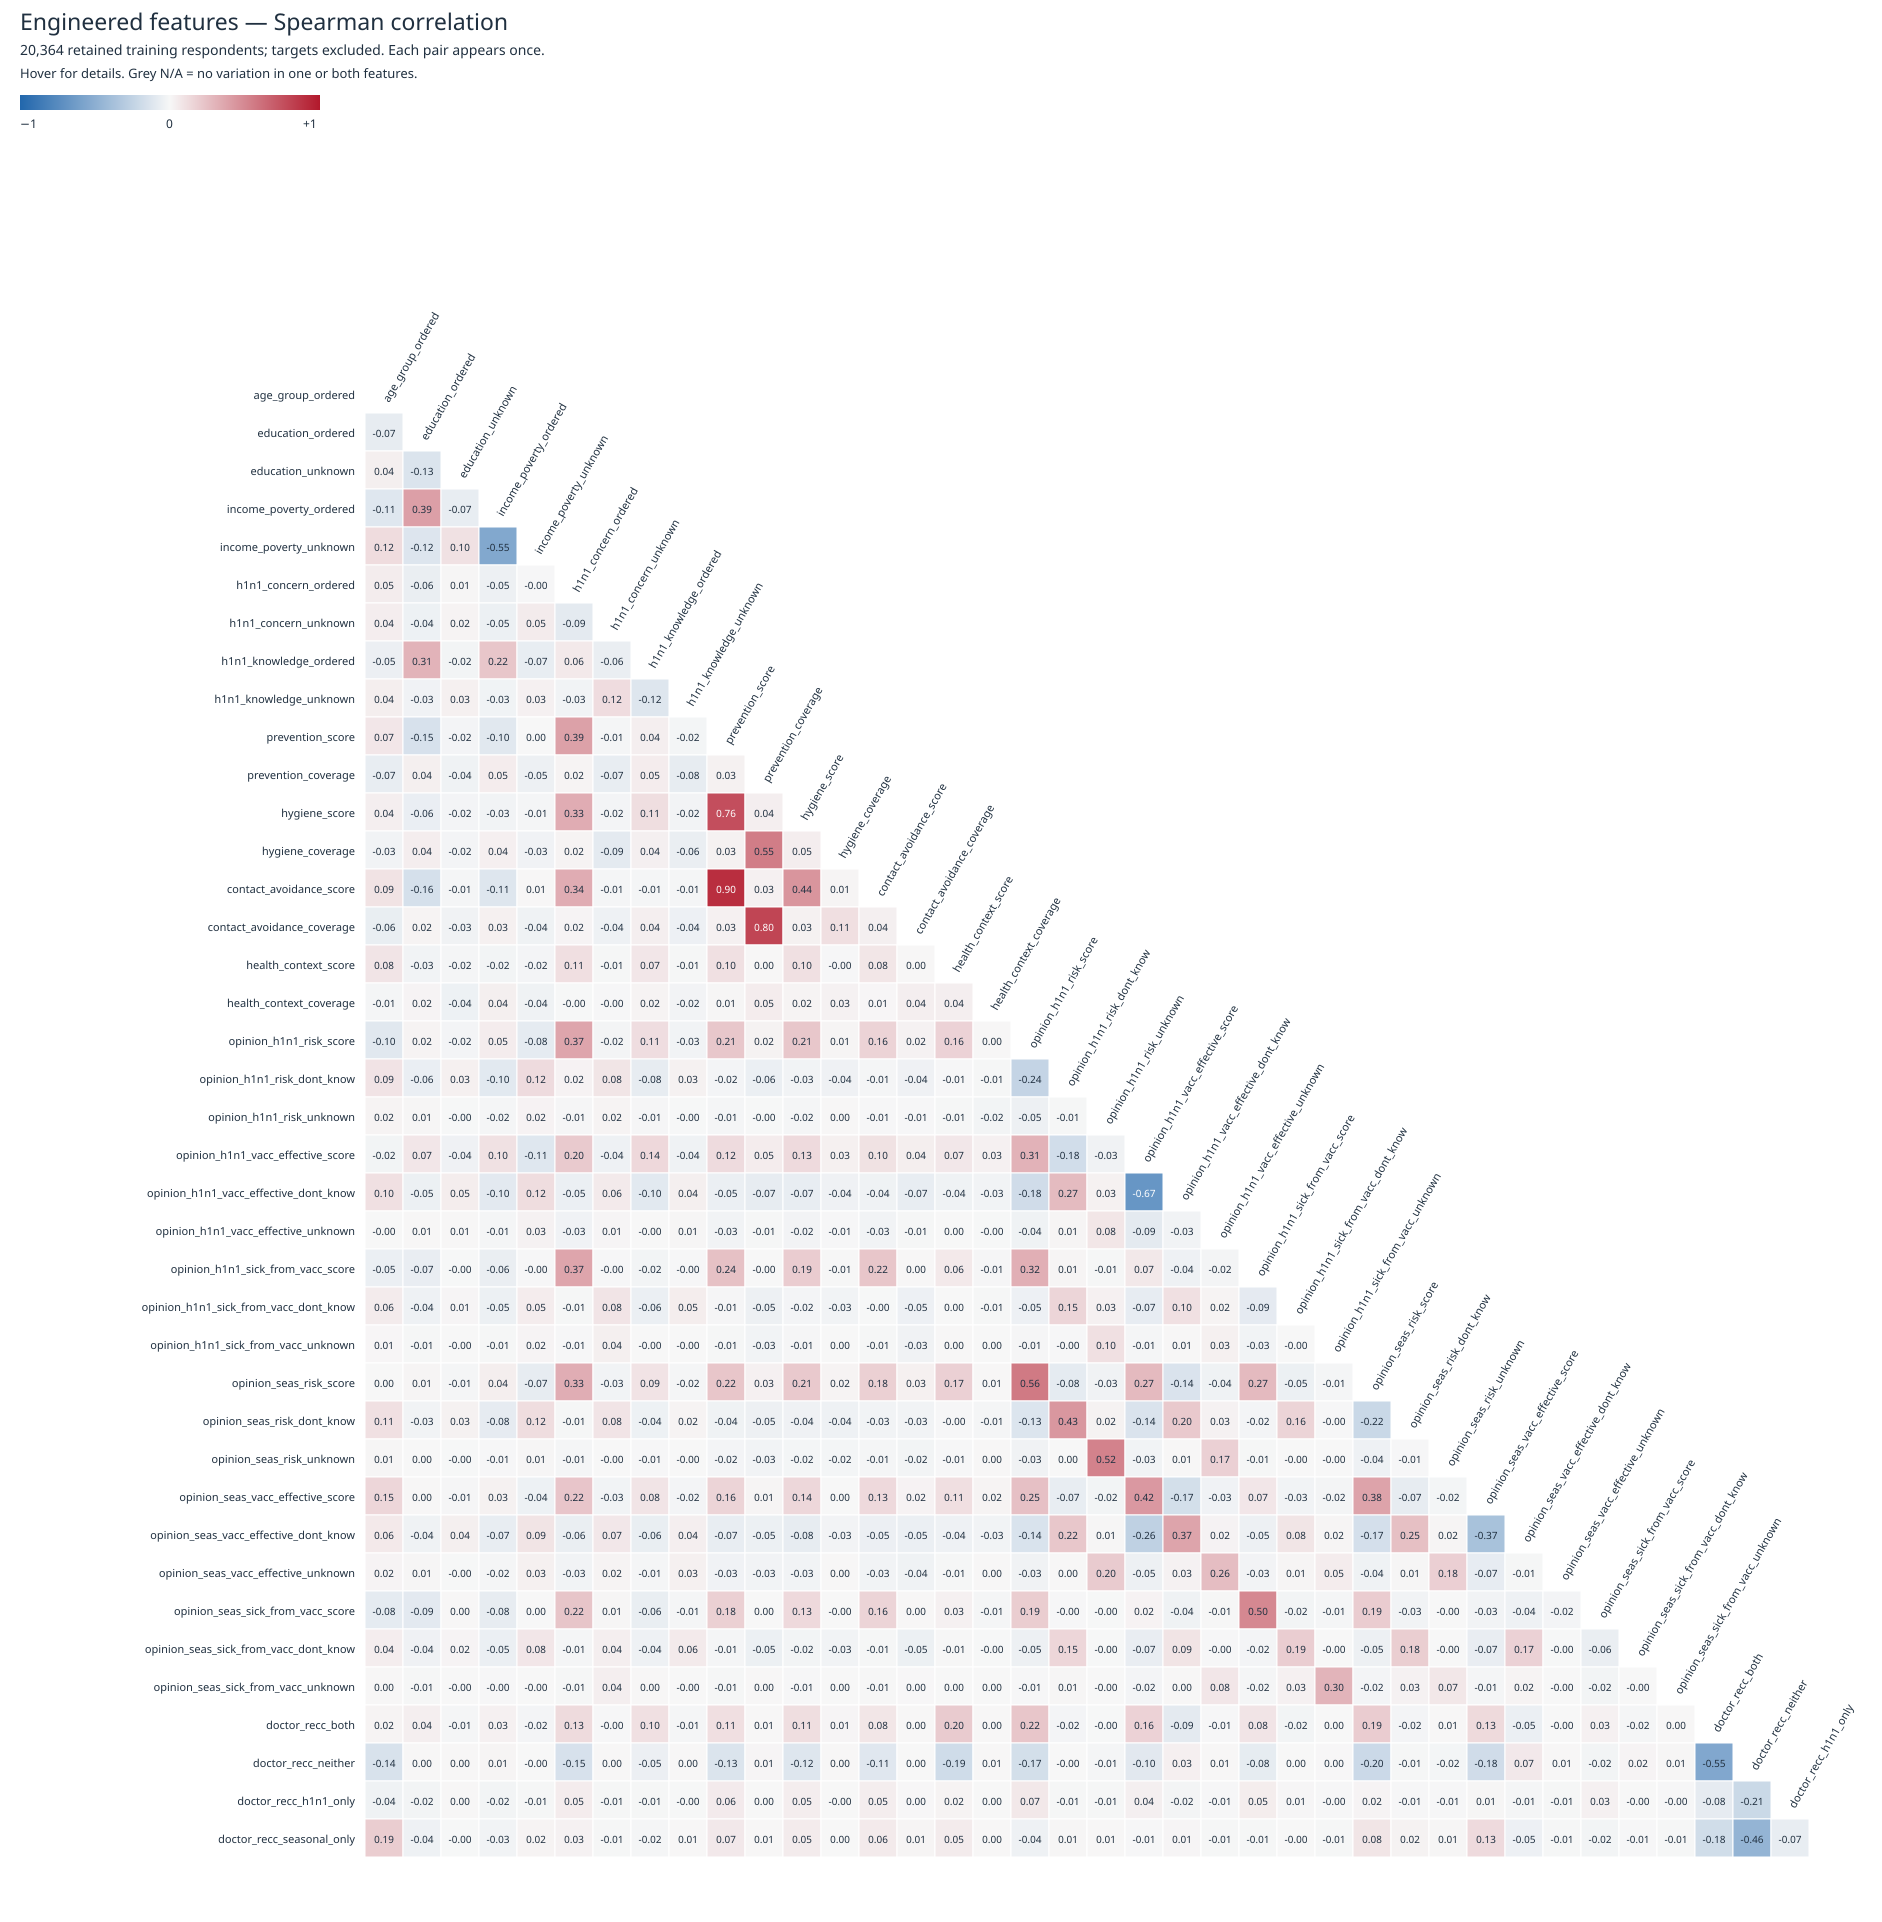

Heatmap: 39 engineered columns; 20,364 training respondents
Constant columns shown as N/A: []
Open the heatmap: /Users/zahra.nourbakhsh/Downloads/ReDI/Vaccine_Prediction_Team_5/Vaccine_Prediction_Team_5/reports/figures/engineered_features_triangular_heatmap.svg


In [7]:
# Uses pandas/NumPy and SVG; no plotting-package installation is required.
from html import escape

heatmap_features = engineered['train'].copy()
# Correlating average ranks gives Spearman correlation, including tied answers.
engineered_correlation = heatmap_features.rank(method='average').corr(method='pearson')
constant_features = heatmap_features.columns[heatmap_features.nunique() <= 1].tolist()
print(f'Heatmap: {len(heatmap_features.columns)} engineered columns; {len(heatmap_features):,} training respondents')
print('Constant columns shown as N/A:', constant_features)

names = engineered_correlation.columns.tolist()
cell = 38
left, top = 365, 375
size = len(names) * cell
width, height = left + size + 35, top + size + 65

def engineered_heatmap_colour(value):
    if not np.isfinite(value):
        return '#dddddd'
    end = (178, 24, 43) if value >= 0 else (33, 102, 172)
    return '#' + ''.join(f'{round(247 + (channel-247)*min(abs(value), 1)):02x}' for channel in end)

svg_parts = [
    f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-labelledby="engineered-heatmap-title engineered-heatmap-desc">',
    '<title id="engineered-heatmap-title">Triangular correlations of engineered features</title>',
    f'<desc id="engineered-heatmap-desc">Lower-triangle Spearman correlation matrix for {len(names)} engineered columns across {len(heatmap_features):,} training respondents. Constant columns are N/A.</desc>',
    '<defs><linearGradient id="engineered-correlation-legend"><stop offset="0%" stop-color="#2166ac"/><stop offset="50%" stop-color="#f7f7f7"/><stop offset="100%" stop-color="#b2182b"/></linearGradient></defs>',
    '<rect width="100%" height="100%" fill="white"/>',
    '<g font-family="sans-serif" fill="#203040">',
    '<text x="20" y="30" font-size="23">Engineered features — Spearman correlation</text>',
    f'<text x="20" y="55" font-size="14">{len(heatmap_features):,} retained training respondents; targets excluded. Each pair appears once.</text>',
    '<text x="20" y="78" font-size="13">Hover for details. Grey N/A = no variation in one or both features.</text>',
    '<rect x="20" y="95" width="300" height="15" fill="url(#engineered-correlation-legend)"/>',
    '<text x="20" y="128" font-size="12">−1</text><text x="166" y="128" font-size="12">0</text><text x="303" y="128" font-size="12">+1</text>',
]
for i, row_name in enumerate(names):
    svg_parts.append(f'<text x="{left-10}" y="{top+i*cell+24}" text-anchor="end" font-size="11">{escape(row_name)}</text>')
    # Follow the edge of the triangle to keep column labels close to cells.
    if i < len(names)-1:
        svg_parts.append(f'<text transform="translate({left+i*cell+24},{top+(i+1)*cell-10}) rotate(-60)" font-size="11">{escape(row_name)}</text>')
    for j in range(i):
        value = float(engineered_correlation.iloc[i, j])
        pair_count = int(heatmap_features[[row_name, names[j]]].notna().all(axis=1).sum())
        x, y = left+j*cell, top+i*cell
        text = f'{value:.2f}' if np.isfinite(value) else 'N/A'
        detail = f'{row_name} × {names[j]}: rho={value:.4f}; n={pair_count:,}' if np.isfinite(value) else f'{row_name} × {names[j]}: undefined (constant feature); n={pair_count:,}'
        ink = 'white' if np.isfinite(value) and abs(value) > .6 else '#203040'
        svg_parts.append(f'<g><title>{escape(detail)}</title><rect class="correlation-cell" x="{x}" y="{y}" width="{cell}" height="{cell}" fill="{engineered_heatmap_colour(value)}" stroke="white"/><text x="{x+cell/2}" y="{y+24}" text-anchor="middle" fill="{ink}" font-size="10">{text}</text></g>')
svg_parts.append('</g></svg>')
engineered_heatmap_svg = ''.join(svg_parts)
engineered_heatmap_path = ROOT / 'reports/figures/engineered_features_triangular_heatmap.svg'
engineered_heatmap_path.parent.mkdir(parents=True, exist_ok=True)
engineered_heatmap_path.write_text(engineered_heatmap_svg)

# Verify symmetry, valid range, and exactly one displayed cell for every pair.
import xml.etree.ElementTree as ET
assert np.allclose(engineered_correlation.to_numpy(), engineered_correlation.to_numpy().T, equal_nan=True)
assert engineered_correlation.abs().max().max() <= 1.00000001
heatmap_tree = ET.fromstring(engineered_heatmap_svg)
assert len(heatmap_tree.findall('.//{http://www.w3.org/2000/svg}rect[@class="correlation-cell"]')) == len(names)*(len(names)-1)//2
for feature in constant_features:
    assert engineered_correlation[feature].isna().all()
try:
    from IPython.display import SVG, display
except ImportError:
    print('Open the heatmap:', engineered_heatmap_path)
else:
    display(SVG(data=engineered_heatmap_svg))


### Engineered features versus the two vaccination targets

Each row is an engineered feature. The two columns show its **Spearman correlation with H1N1 vaccination and seasonal vaccination separately**, using retained training respondents only. Red means higher feature values are associated with higher vaccination uptake; blue means lower uptake. Grey N/A indicates a constant feature. Hover for the exact coefficient and respondent count. The table below shows the same coefficients.

These are **unadjusted associations, not causal effects or independent model contributions**. Correlation can miss non-monotonic patterns; overlapping features may reflect the same information. Unavailable scores stored as zero can also influence these associations, so inspect coverage alongside each score. Targets are used for this training-only descriptive chart, never as input features. Validation/test data are excluded. Compare held-out model performance with and without feature families to assess predictive contribution.

Age now appears as `age_group_ordered` in the heatmap. Its five original groups are also summarized in the uptake table below. Differences in uptake do not imply causation.


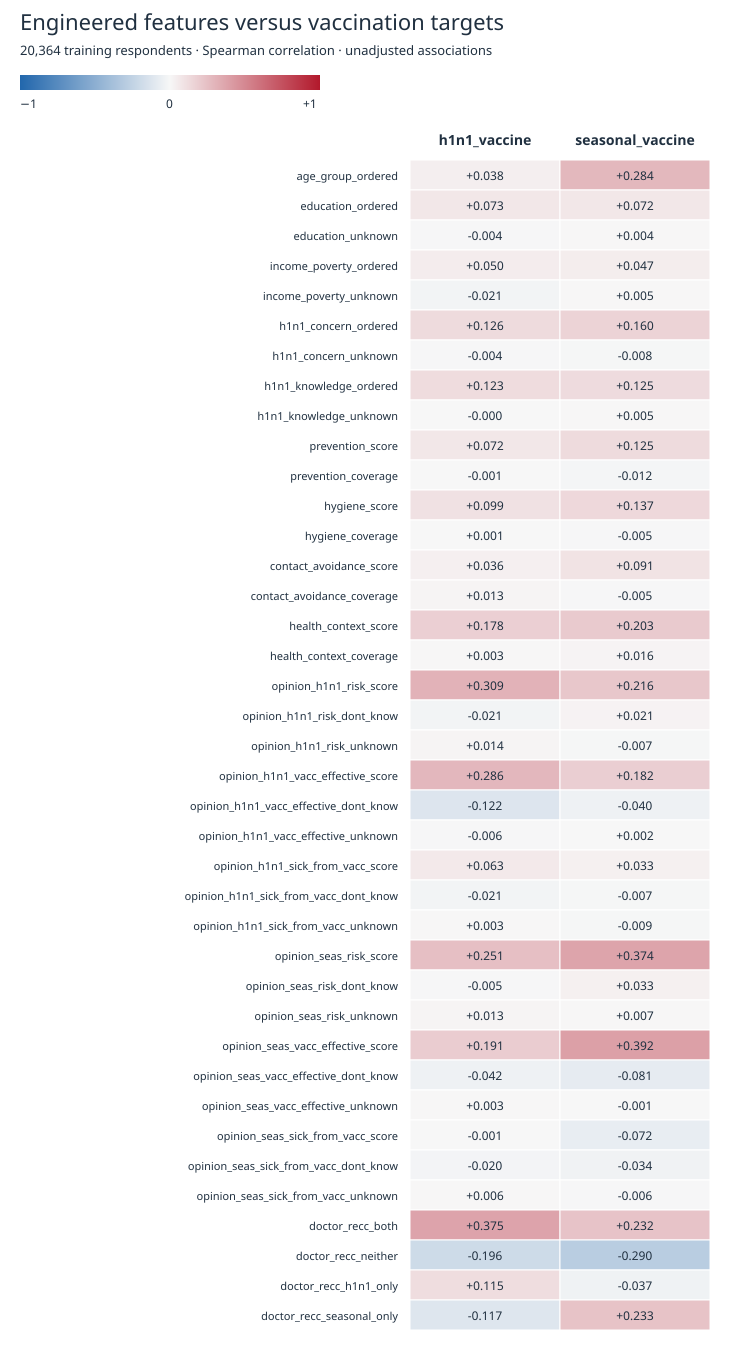

Open the target heatmap: /Users/zahra.nourbakhsh/Downloads/ReDI/Vaccine_Prediction_Team_5/Vaccine_Prediction_Team_5/reports/figures/engineered_features_target_heatmap.svg
                                       h1n1_vaccine  seasonal_vaccine
age_group_ordered                             0.038             0.284
education_ordered                             0.073             0.072
education_unknown                            -0.004             0.004
income_poverty_ordered                        0.050             0.047
income_poverty_unknown                       -0.021             0.005
h1n1_concern_ordered                          0.126             0.160
h1n1_concern_unknown                         -0.004            -0.008
h1n1_knowledge_ordered                        0.123             0.125
h1n1_knowledge_unknown                       -0.000             0.005
prevention_score                              0.072             0.125
prevention_coverage                          -0.001        

In [8]:
from html import escape
import xml.etree.ElementTree as ET

feature_values = engineered['train'].reset_index(drop=True)
training_targets = baseline['train'][TARGETS].reset_index(drop=True)
assert len(feature_values) == len(training_targets)
assert training_targets.isin([0, 1]).all().all()
assert not set(TARGETS) & set(feature_values.columns)
ranked = pd.concat([feature_values, training_targets], axis=1).rank(method='average')
feature_target_correlations = ranked.corr().loc[feature_values.columns, TARGETS]

row_height, column_width = 30, 150
left, top = 410, 160
width = left + 2*column_width + 35
height = top + len(feature_values.columns)*row_height + 40

def target_heatmap_colour(value):
    if not np.isfinite(value):
        return '#dddddd'
    end = (178, 24, 43) if value >= 0 else (33, 102, 172)
    return '#' + ''.join(f'{round(247+(channel-247)*min(abs(value),1)):02x}' for channel in end)

svg_parts = [
    f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-labelledby="target-heatmap-title target-heatmap-desc">',
    '<title id="target-heatmap-title">Engineered features versus vaccination targets</title>',
    f'<desc id="target-heatmap-desc">Spearman correlations for {len(feature_values.columns)} engineered features with each vaccination target in {len(feature_values):,} training respondents. Associations do not establish causal effects.</desc>',
    '<defs><linearGradient id="target-correlation-legend"><stop offset="0%" stop-color="#2166ac"/><stop offset="50%" stop-color="#f7f7f7"/><stop offset="100%" stop-color="#b2182b"/></linearGradient></defs>',
    '<rect width="100%" height="100%" fill="white"/>',
    '<g font-family="sans-serif" fill="#203040">',
    '<text x="20" y="30" font-size="22">Engineered features versus vaccination targets</text>',
    f'<text x="20" y="55" font-size="13">{len(feature_values):,} training respondents · Spearman correlation · unadjusted associations</text>',
    '<rect x="20" y="75" width="300" height="15" fill="url(#target-correlation-legend)"/>',
    '<text x="20" y="108" font-size="12">−1</text><text x="166" y="108" font-size="12">0</text><text x="303" y="108" font-size="12">+1</text>',
]
for j, target in enumerate(TARGETS):
    svg_parts.append(f'<text x="{left+j*column_width+column_width/2}" y="{top-15}" text-anchor="middle" font-size="14" font-weight="bold">{escape(target)}</text>')
for i, feature in enumerate(feature_values.columns):
    y = top+i*row_height
    svg_parts.append(f'<text x="{left-12}" y="{y+20}" text-anchor="end" font-size="11">{escape(feature)}</text>')
    for j, target in enumerate(TARGETS):
        value = float(feature_target_correlations.loc[feature, target])
        x = left+j*column_width
        text = f'{value:+.3f}' if np.isfinite(value) else 'N/A'
        tip = f'{feature} versus {target}: rho={value:.5f}; n={len(feature_values):,}' if np.isfinite(value) else f'{feature} versus {target}: undefined because the feature is constant'
        ink = 'white' if np.isfinite(value) and abs(value) > .6 else '#203040'
        svg_parts.append(f'<g><title>{escape(tip)}</title><rect class="target-correlation-cell" x="{x}" y="{y}" width="{column_width}" height="{row_height}" fill="{target_heatmap_colour(value)}" stroke="white"/><text x="{x+column_width/2}" y="{y+20}" text-anchor="middle" font-size="12" fill="{ink}">{text}</text></g>')
svg_parts.append('</g></svg>')
feature_target_heatmap_svg = ''.join(svg_parts)
feature_target_heatmap_path = ROOT / 'reports/figures/engineered_features_target_heatmap.svg'
feature_target_heatmap_path.parent.mkdir(parents=True, exist_ok=True)
feature_target_heatmap_path.write_text(feature_target_heatmap_svg)

# Verify every feature-target cell and undefined constant-column correlations.
assert feature_target_correlations.shape == (len(feature_values.columns), len(TARGETS))
assert feature_target_correlations.abs().max().max() <= 1.00000001
for col in feature_values:
    for target in TARGETS:
        expected = feature_values[col].rank().corr(training_targets[target].rank()) if feature_values[col].nunique() > 1 else np.nan
        assert np.isclose(feature_target_correlations.loc[col, target], expected, equal_nan=True)
chart_tree = ET.fromstring(feature_target_heatmap_svg)
assert len(chart_tree.findall('.//{http://www.w3.org/2000/svg}rect[@class="target-correlation-cell"]')) == feature_values.shape[1]*2
try:
    from IPython.display import SVG, display
except ImportError:
    print('Open the target heatmap:', feature_target_heatmap_path)
else:
    display(SVG(data=feature_target_heatmap_svg))
display(feature_target_correlations.round(3))

# Show original age-group uptake separately: it is not an engineered score.
age_order = ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years']
age_target_data = pd.concat([answers['train'][['age_group']].reset_index(drop=True), training_targets], axis=1)
age_uptake = age_target_data.groupby('age_group')[TARGETS].mean().mul(100).reindex(age_order)
age_uptake.columns = ['H1N1 vaccinated (%)', 'Seasonal vaccinated (%)']
age_uptake['respondents'] = age_target_data.groupby('age_group').size().reindex(age_order)
print('Vaccination uptake by original age group — retained training respondents:')
display(age_uptake.round(1))


### Final predictors versus vaccination targets — behavioral scores replace individual answers

This new heatmap shows **every retained model input** against the H1N1 and seasonal targets separately. The seven original behavioral questions are represented only through prevention, hygiene and contact-avoidance scores plus their coverage; their individual encoded columns are absent. The fourth score, health context, summarizes three health-related questions, whose individual variables are retained.

Ordered age (18–34 is score 0), separately scored vaccine-specific opinions, doctor recommendations and other retained inputs remain visible separately. Scroll vertically or open the SVG to inspect the full chart. Grey N/A marks constant columns. Red/blue indicate positive/negative Spearman association, not independent model importance or causation. All coefficients use training respondents only.


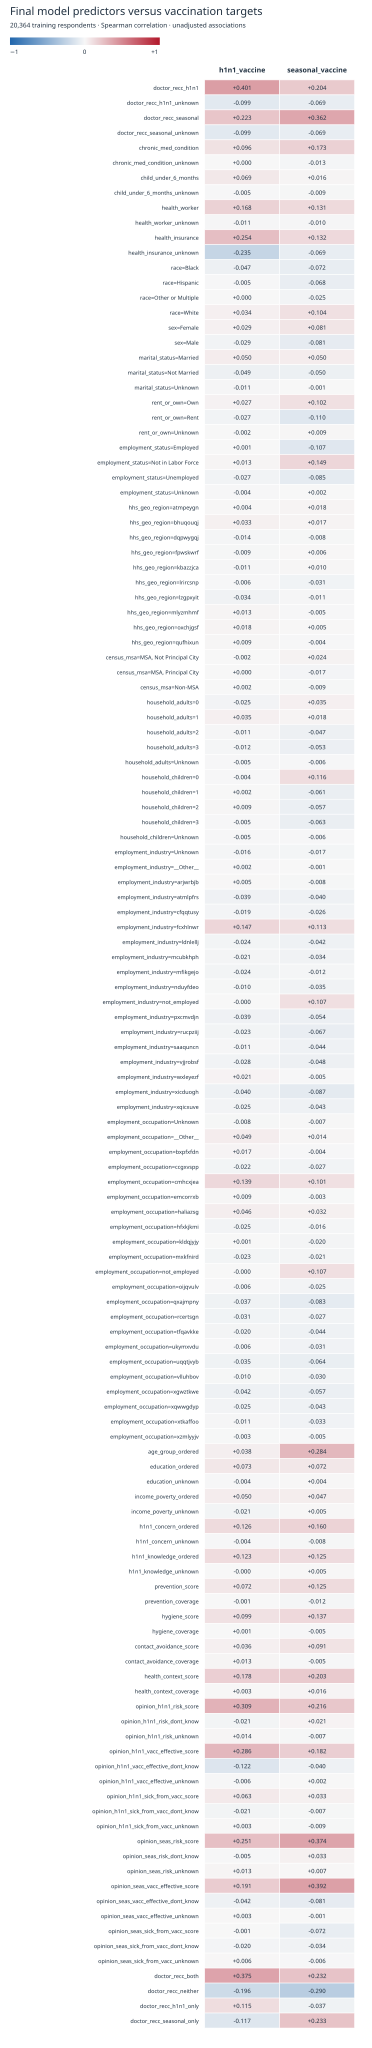

Open the final-predictor target heatmap: /Users/zahra.nourbakhsh/Downloads/ReDI/Vaccine_Prediction_Team_5/Vaccine_Prediction_Team_5/reports/figures/final_features_target_heatmap.svg
                                       h1n1_vaccine  seasonal_vaccine
doctor_recc_h1n1                              0.401             0.204
doctor_recc_h1n1_unknown                     -0.099            -0.069
doctor_recc_seasonal                          0.223             0.362
doctor_recc_seasonal_unknown                 -0.099            -0.069
chronic_med_condition                         0.096             0.173
chronic_med_condition_unknown                 0.000            -0.013
child_under_6_months                          0.069             0.016
child_under_6_months_unknown                 -0.005            -0.009
health_worker                                 0.168             0.131
health_worker_unknown                        -0.011            -0.010
health_insurance                              0.

In [9]:
from html import escape
import xml.etree.ElementTree as ET

final_feature_values = matrices['train'].reset_index(drop=True)
final_training_targets = baseline['train'][TARGETS].reset_index(drop=True)
assert len(final_feature_values) == len(final_training_targets)
assert final_training_targets.isin([0, 1]).all().all()
assert not set(TARGETS) & set(final_feature_values.columns)
final_ranked = pd.concat([final_feature_values, final_training_targets], axis=1).rank(method='average')
final_feature_target_correlations = final_ranked.corr().loc[final_feature_values.columns, TARGETS]

row_height, column_width = 30, 150
left, top = 410, 160
width = left + 2*column_width + 35
height = top + len(final_feature_values.columns)*row_height + 40

def final_target_heatmap_colour(value):
    if not np.isfinite(value):
        return '#dddddd'
    end = (178, 24, 43) if value >= 0 else (33, 102, 172)
    return '#' + ''.join(f'{round(247+(channel-247)*min(abs(value),1)):02x}' for channel in end)

final_svg_parts = [
    f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-labelledby="final-target-heatmap-title final-target-heatmap-desc">',
    '<title id="final-target-heatmap-title">Final model predictors versus vaccination targets</title>',
    f'<desc id="final-target-heatmap-desc">Spearman correlations for {len(final_feature_values.columns)} final model predictors with each vaccination target in {len(final_feature_values):,} training respondents. Associations do not establish causal effects.</desc>',
    '<defs><linearGradient id="final-target-correlation-legend"><stop offset="0%" stop-color="#2166ac"/><stop offset="50%" stop-color="#f7f7f7"/><stop offset="100%" stop-color="#b2182b"/></linearGradient></defs>',
    '<rect width="100%" height="100%" fill="white"/>',
    '<g font-family="sans-serif" fill="#203040">',
    '<text x="20" y="30" font-size="22">Final model predictors versus vaccination targets</text>',
    f'<text x="20" y="55" font-size="13">{len(final_feature_values):,} training respondents · Spearman correlation · unadjusted associations</text>',
    '<rect x="20" y="75" width="300" height="15" fill="url(#final-target-correlation-legend)"/>',
    '<text x="20" y="108" font-size="12">−1</text><text x="166" y="108" font-size="12">0</text><text x="303" y="108" font-size="12">+1</text>',
]
for j, target in enumerate(TARGETS):
    final_svg_parts.append(f'<text x="{left+j*column_width+column_width/2}" y="{top-15}" text-anchor="middle" font-size="14" font-weight="bold">{escape(target)}</text>')
for i, feature in enumerate(final_feature_values.columns):
    y = top+i*row_height
    final_svg_parts.append(f'<text x="{left-12}" y="{y+20}" text-anchor="end" font-size="11">{escape(feature)}</text>')
    for j, target in enumerate(TARGETS):
        value = float(final_feature_target_correlations.loc[feature, target])
        x = left+j*column_width
        text = f'{value:+.3f}' if np.isfinite(value) else 'N/A'
        tip = f'{feature} versus {target}: rho={value:.5f}; n={len(final_feature_values):,}' if np.isfinite(value) else f'{feature} versus {target}: undefined because the feature is constant'
        ink = 'white' if np.isfinite(value) and abs(value) > .6 else '#203040'
        final_svg_parts.append(f'<g><title>{escape(tip)}</title><rect class="target-correlation-cell" x="{x}" y="{y}" width="{column_width}" height="{row_height}" fill="{final_target_heatmap_colour(value)}" stroke="white"/><text x="{x+column_width/2}" y="{y+20}" text-anchor="middle" font-size="12" fill="{ink}">{text}</text></g>')
final_svg_parts.append('</g></svg>')
final_feature_target_heatmap_svg = ''.join(final_svg_parts)
final_feature_target_heatmap_path = ROOT / 'reports/figures/final_features_target_heatmap.svg'
final_feature_target_heatmap_path.parent.mkdir(parents=True, exist_ok=True)
final_feature_target_heatmap_path.write_text(final_feature_target_heatmap_svg)

# Verify every feature-target cell and undefined constant-column correlations.
assert final_feature_target_correlations.shape == (len(final_feature_values.columns), len(TARGETS))
assert final_feature_target_correlations.abs().max().max() <= 1.00000001
for col in final_feature_values:
    for target in TARGETS:
        expected = final_feature_values[col].rank().corr(final_training_targets[target].rank()) if final_feature_values[col].nunique() > 1 else np.nan
        assert np.isclose(final_feature_target_correlations.loc[col, target], expected, equal_nan=True)
final_chart_tree = ET.fromstring(final_feature_target_heatmap_svg)
assert len(final_chart_tree.findall('.//{http://www.w3.org/2000/svg}rect[@class="target-correlation-cell"]')) == final_feature_values.shape[1]*2
try:
    from IPython.display import SVG, display
except ImportError:
    print('Open the final-predictor target heatmap:', final_feature_target_heatmap_path)
else:
    display(SVG(data=final_feature_target_heatmap_svg))
display(final_feature_target_correlations.round(3))



## 7. Save one feature-engineered dataset version

Save `train.csv`, `validation.csv`, `test.csv` and `preprocessing_state.json` in `data_processed/ml_features/`. The original baseline files are preserved for comparison. The JSON includes feature recipes, ordered mappings, column order and the original training-fitted encoding state. Use this notebook's `engineer_features` function and these rules to reproduce the transformations; it contains the full implementation.

Each table includes an ID; train/validation also include both outcomes. Select **only** `feature_columns` for model inputs. When comparing this version with the baseline, train and evaluate both on their identical respondent partitions. No model has been fitted yet.


In [10]:
OUT.mkdir(parents=True, exist_ok=True)
prepared = {}
for name, matrix in matrices.items():
    parts = [baseline[name][[ID]], matrix]
    if name != 'test':
        parts.append(baseline[name][TARGETS])
    prepared[name] = pd.concat(parts, axis=1)
    assert prepared[name][ID].tolist() == baseline[name][ID].tolist()
    if name != 'test':
        pd.testing.assert_frame_equal(prepared[name][TARGETS], baseline[name][TARGETS])
    prepared[name].to_csv(OUT / f'{name}.csv', index=False)
    pd.testing.assert_frame_equal(pd.read_csv(OUT / f'{name}.csv'), prepared[name], check_dtype=False)
feature_state = {
    'version': 'feature_engineering_v11_four_recommendation_patterns',
    'implementation': 'notebook/04_feature_engineering.ipynb',
    'feature_columns': feature_columns,
    'engineered_columns': engineered['train'].columns.tolist(),
    'replaced_baseline_columns': replaced_columns,
    'replaced_behavioral_columns': behavior_replaced_columns,
    'replaced_ordinal_columns': ordinal_replaced_columns,
    'replaced_opinion_columns': opinion_replaced_columns,
    'original_behavioral_sources': original_behavior_columns,
    'behavioral_representation': 'Prevention, hygiene and contact-avoidance scores with coverage replace seven individual behavioral questions. Health-context score and its source variables remain separate.',
    'retained_baseline_columns': retained_columns,
    'ordinal_maps': ORDINAL_MAPS,
    'ordinal_max': ORDINAL_MAX,
    'age_encoding': 'One ordered age column: 18-34=0, 35-44=.25, 45-54=.5, 55-64=.75, 65+=1. Ranks are not exact ages; new missing ages require explicit review.',
    'income_encoding': 'Ordered income (0, 0.5, 1) plus unknown flag only; no income-band indicators.',
    'nominal_encoding': 'Full indicators for every observed nominal category; no reference group omitted. Original numeric binary questions and insurance keep compact value/unknown columns.',
    'joint_doctor_recommendations': {
        'sources': ['doctor_recc_h1n1', 'doctor_recc_seasonal'],
        'doctor_recc_both': '1 only when both original answers are 1; otherwise 0',
        'doctor_recc_neither': '1 only when both original answers are 0; otherwise 0',
        'doctor_recc_h1n1_only': '1 only when H1N1 recommendation=1 and seasonal recommendation=0; otherwise 0',
        'doctor_recc_seasonal_only': '1 only when H1N1 recommendation=0 and seasonal recommendation=1; otherwise 0',
        'missing_policy': 'Any missing original answer makes all four pattern indicators 0; preserve original recommendation values and missing flags.',
    },
    'behavior_scores': BEHAVIOR_SCORES,
    'opinion_columns': OPINION_COLUMNS,
    'opinion_score_map': OPINION_SCORE_MAP,
    'opinion_encoding': 'Each question separately: 1=0,2=1/3,4=2/3,5=1; code3 has dont_know=1, NaN has unknown=1; unavailable scores stored as 0 with flags. No cross-vaccine averaging.',
    'aggregate_missing_policy': 'Behavior and health-context means use known binary answers only and require minimum coverage; unavailable scores stored as 0 with coverage retained. Vaccine-specific opinions use separate ordered scores, dont-know flags and missing flags; no combined opinion summaries.',
    'baseline_preprocessing_state': baseline_state,
    'fit_source': 'All new mappings fixed a priori; baseline vocabulary/grouping learned on training only.',
    'cross_validation': 'Refit baseline vocabulary and rare grouping on each fold training partition.',
    'codebook_source': 'https://www.drivendata.org/competitions/66/flushot-learning/page/211/',
}
(OUT / 'preprocessing_state.json').write_text(json.dumps(feature_state, indent=2) + '\n')
X_train = prepared['train'][feature_columns]
y_train = prepared['train'][TARGETS]
X_validation = prepared['validation'][feature_columns]
y_validation = prepared['validation'][TARGETS]
X_test = prepared['test'][feature_columns]
display(pd.DataFrame([{'dataset': n, 'rows': len(t), 'predictors': len(feature_columns),
                      'missing_cells': int(t.isna().sum().sum())} for n, t in prepared.items()]))
print('Output folder:', OUT)
print('Baseline predictors:', len(baseline_state['encoded_columns']))
print('Removed ordinal encoding columns:', len(ordinal_replaced_columns))
print('Removed behavioral encoding columns:', len(behavior_replaced_columns))
print('Removed opinion encoding columns:', len(opinion_replaced_columns))
print('Engineered columns:', len(engineered['train'].columns))
print('Final predictors:', len(feature_columns))


      dataset   rows  predictors  missing_cells
0       train  20364         130              0
1  validation   5341         130              0
2        test  26708         130              0
Output folder: /Users/zahra.nourbakhsh/Downloads/ReDI/Vaccine_Prediction_Team_5/Vaccine_Prediction_Team_5/data_processed/ml_features
Baseline predictors: 164
Removed ordinal encoding columns: 23
Removed behavioral encoding columns: 14
Removed opinion encoding columns: 36
Engineered columns: 39
Final predictors: 130
